## **Movie Recommendation System**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv(r'C:\Users\Tech\Downloads\tmdb_5000_movies.csv')
df.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   str    
 2   homepage              1712 non-null   str    
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   str    
 5   original_language     4803 non-null   str    
 6   original_title        4803 non-null   str    
 7   overview              4800 non-null   str    
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   str    
 10  production_countries  4803 non-null   str    
 11  release_date          4802 non-null   str    
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   str    
 15  status                4803 non-n

In [5]:
df.isna().sum()

budget                     0
genres                     0
homepage                3091
id                         0
keywords                   0
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
dtype: int64

In [6]:
df.isna().mean()*100

budget                   0.000000
genres                   0.000000
homepage                64.355611
id                       0.000000
keywords                 0.000000
original_language        0.000000
original_title           0.000000
overview                 0.062461
popularity               0.000000
production_companies     0.000000
production_countries     0.000000
release_date             0.020820
revenue                  0.000000
runtime                  0.041641
spoken_languages         0.000000
status                   0.000000
tagline                 17.572351
title                    0.000000
vote_average             0.000000
vote_count               0.000000
dtype: float64

In [7]:
#Dropping the columnn "homepage" as it has many missing values and it is not a feature that can be used for analysis.
df.drop(columns=['homepage'], inplace=True)

In [8]:
#Dropping the rows with missing values in the columns "tagline", "release_date" and "overview" as they are important features for analysis.
df.dropna(subset=['tagline', 'release_date', 'overview'], inplace=True)

In [9]:
#Before I sort the missingness in "runtime", let's check the distribution to see whether we will use mean median to impute the missing values or we will drop the rows with missing values in runtime.
df['runtime'].describe()

count    3959.000000
mean      108.053296
std        20.685888
min         0.000000
25%        94.000000
50%       104.000000
75%       118.000000
max       338.000000
Name: runtime, dtype: float64

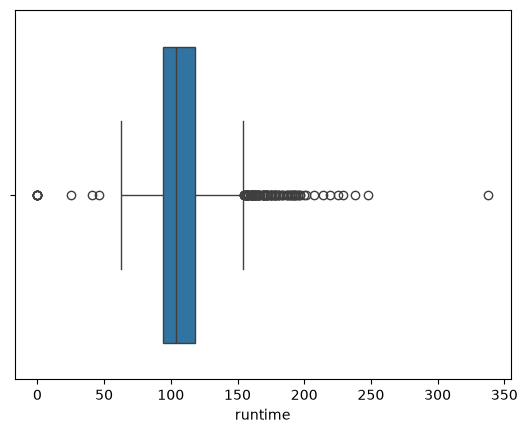

In [10]:
sns.boxplot(x=df['runtime'])
plt.show()

In [11]:
df['runtime']=df['runtime'].fillna(df['runtime'].median())

In [12]:
print("Missing:", df['runtime'].isna().sum())
print("Zero runtimes:", (df['runtime'] == 0).sum())
print("Negative runtimes:", (df['runtime'] < 0).sum())

Missing: 0
Zero runtimes: 7
Negative runtimes: 0


In [13]:
#replacing the zero valuesin runtime with the median value of the column.
df['runtime'] = df['runtime'].replace(0, np.nan)

In [14]:
df['runtime'] = df['runtime'].fillna(df['runtime'].median())

In [15]:
print("Missing:", df['runtime'].isna().sum())
print("Zero runtimes:", (df['runtime'] == 0).sum())
print("Negative runtimes:", (df['runtime'] < 0).sum())

Missing: 0
Zero runtimes: 0
Negative runtimes: 0


In [16]:
df.isna().sum()

budget                  0
genres                  0
id                      0
keywords                0
original_language       0
original_title          0
overview                0
popularity              0
production_companies    0
production_countries    0
release_date            0
revenue                 0
runtime                 0
spoken_languages        0
status                  0
tagline                 0
title                   0
vote_average            0
vote_count              0
dtype: int64

In [17]:
#release_date is a date column, so we will convert it to datetime format
df['release_date'] = pd.to_datetime(df['release_date'])

In [18]:
columns = ['genres', 'keywords', 'overview', 'title', 'tagline']

# Check missing values
print(df[columns].isna().sum())

# Check empty strings
print((df[columns] == '').sum())

# View sample values
for col in columns:
    print(f"\n--- {col.upper()} ---")
    print(df[col].head(5).to_list())

genres      0
keywords    0
overview    0
title       0
tagline     0
dtype: int64
genres      0
keywords    0
overview    0
title       0
tagline     0
dtype: int64

--- GENRES ---
['[{"id": 28, "name": "Action"}, {"id": 12, "name": "Adventure"}, {"id": 14, "name": "Fantasy"}, {"id": 878, "name": "Science Fiction"}]', '[{"id": 12, "name": "Adventure"}, {"id": 14, "name": "Fantasy"}, {"id": 28, "name": "Action"}]', '[{"id": 28, "name": "Action"}, {"id": 12, "name": "Adventure"}, {"id": 80, "name": "Crime"}]', '[{"id": 28, "name": "Action"}, {"id": 80, "name": "Crime"}, {"id": 18, "name": "Drama"}, {"id": 53, "name": "Thriller"}]', '[{"id": 28, "name": "Action"}, {"id": 12, "name": "Adventure"}, {"id": 878, "name": "Science Fiction"}]']

--- KEYWORDS ---
['[{"id": 1463, "name": "culture clash"}, {"id": 2964, "name": "future"}, {"id": 3386, "name": "space war"}, {"id": 3388, "name": "space colony"}, {"id": 3679, "name": "society"}, {"id": 3801, "name": "space travel"}, {"id": 9685, "name

In [19]:
#Remove trailing and leading spaces from the string columns
columns = ['genres', 'keywords', 'overview', 'title', 'tagline']

for col in columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

In [20]:
import json

In [21]:
def extract_names(value):
    if pd.isna(value):
        return []

    try:
        items = json.loads(value)
        return [item['name'] for item in items]
    except (json.JSONDecodeError, TypeError, KeyError):
        return []

In [22]:
df['genres'] = df['genres'].apply(extract_names)

In [23]:
df['keywords'] = df['keywords'].apply(extract_names)

In [24]:
df['production_companies'] = df['production_companies'].apply(extract_names)

In [25]:
df['spoken_languages'] = df['spoken_languages'].apply(extract_names)

In [26]:
df['production_countries'] = df['production_countries'].apply(extract_names)

In [27]:
print(df[['genres', 'keywords']].head(5))

                                          genres  \
0  [Action, Adventure, Fantasy, Science Fiction]   
1                   [Adventure, Fantasy, Action]   
2                     [Action, Adventure, Crime]   
3               [Action, Crime, Drama, Thriller]   
4           [Action, Adventure, Science Fiction]   

                                            keywords  
0  [culture clash, future, space war, space colon...  
1  [ocean, drug abuse, exotic island, east india ...  
2  [spy, based on novel, secret agent, sequel, mi...  
3  [dc comics, crime fighter, terrorist, secret i...  
4  [based on novel, mars, medallion, space travel...  


In [28]:
#Checking for empty lists in the columns "genres" and "keywords"
print("Empty genres:", (df['genres'].apply(len) == 0).sum())
print("Empty keywords:", (df['keywords'].apply(len) == 0).sum())

Empty genres: 3
Empty keywords: 200


In [29]:
#Investigating the movies with empty lists in the columns "genres" and "keywords"
# Movies with empty genres
empty_genres = df[df['genres'].apply(lambda x: len(x) == 0)]
# Movies with empty keywords
empty_keywords = df[df['keywords'].apply(lambda x: len(x) == 0)]

display(empty_genres[['title', 'genres']])
display(empty_keywords[['title', 'keywords']].head(10))

,title,genres
4105,"The Book of Mormon Movie, Volume 1: The Journey",[]
4569,Mutual Friends,[]
4801,Shanghai Calling,[]


,title,keywords
71,The Mummy: Tomb of the Dragon Emperor,[]
83,The Lovers,[]
323,Sex and the City 2,[]
436,Grown Ups 2,[]
605,Legends of Oz: Dorothy's Return,[]
678,Dragon Blade,[]
857,Imagine That,[]
866,Bullet to the Head,[]
881,Beloved,[]
966,Marmaduke,[]


In [30]:
#For the 3 movies with empty genres, we can manually fill in the genres based on the movie.
genre_updates = {
    'The Book of Mormon Movie, Volume 1: The Journey': ['Drama', 'Adventure'],
    'Mutual Friends': ['Comedy', 'Romance'],
    'Shanghai Calling': ['Romance', 'Comedy']
}

In [31]:
for title, genres in genre_updates.items():
    mask = df['title'] == title
    df.loc[mask, 'genres'] = pd.Series(
        [genres] * mask.sum(),
        index=df.index[mask],
        dtype=object
    )

In [32]:
for title in genre_updates:
    print(
        df.loc[df['title'] == title, ['title', 'genres']]
    )

                                                title              genres
4105  The Book of Mormon Movie, Volume 1: The Journey  [Drama, Adventure]
               title             genres
4569  Mutual Friends  [Comedy, Romance]
                 title             genres
4801  Shanghai Calling  [Romance, Comedy]


In [33]:
print("Empty genres:", (df['genres'].apply(len) == 0).sum())

Empty genres: 0


In [34]:
#We will represent the unvailable keywords with an empty list.
df['keywords_text'] = df['keywords'].apply(lambda x: ' '.join(x) if x else '')

In [35]:
print(
    "Empty keyword lists:",
    df['keywords'].apply(lambda x: len(x) == 0).sum()
)

print(
    "Empty keyword text:",
    (df['keywords_text'] == '').sum()
)

Empty keyword lists: 200
Empty keyword text: 200


In [36]:
#Checking whether the movies with empty keywords have any other information that can be used to extract keywords. We will check the columns "overview" . "title" and "tagline" for these movies.
empty_keywords = df[df['keywords'].apply(lambda x: len(x) == 0)]

display(
    empty_keywords[
        ['title', 'genres', 'overview', 'tagline']
    ].tail(10)
)

,title,genres,overview,tagline
4679,Call + Response,[Documentary],Call + Response is a first of its kind feature...,A FILM ABOUT THE WORLD'S 27 MILLION MOST TERRI...
4721,The Work and The Story,[Comedy],"It is July, 2000 Richard Dutcher, the man who ...",Dream big. Make it happen?
4734,Echo Dr.,"[Thriller, Action, Drama, Science Fiction]","When their home security system malfunctions, ...",To Serve & Terminate
4743,The FP,[Comedy],Two rival gangs fight for control of Frazier P...,An Ancient Game Becomes A Deadly Sport.
4757,Bending Steel,[Documentary],"The Cyclone, The Freakshow, The Mermaid Parade...",The Limiting Factor Is The Mind
4760,This Is Martin Bonner,[Drama],"Two men, at opposite ends of the social spectr...",Sometimes You Have to Lose Your Life in Order ...
4763,Smiling Fish & Goat On Fire,"[Comedy, Romance]",Two brothers share a house in LA's Fairfax dis...,"two brothers, four women and the search for Ma..."
4764,Dawn of the Crescent Moon,"[Thriller, Drama, Science Fiction]",A group of college students travel to a small ...,The past is present.
4799,Newlyweds,"[Comedy, Romance]",A newlywed couple's honeymoon is upended by th...,A newlywed couple's honeymoon is upended by th...
4801,Shanghai Calling,"[Romance, Comedy]",When ambitious New York attorney Sam is sent t...,A New Yorker in Shanghai


In [37]:
#Creating a copy of our dataframe then work on duplicates.
data = df.copy()

In [38]:
data.head()

,budget,genres,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,keywords_text
0,237000000,"[Action, Adventure, Fantasy, Science Fiction]",19995,"[culture clash, future, space war, space colon...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[Ingenious Film Partners, Twentieth Century Fo...","[United States of America, United Kingdom]",2009-12-10,2787965087,162.0,"[English, Español]",Released,Enter the World of Pandora.,Avatar,7.2,11800,culture clash future space war space colony so...
1,300000000,"[Adventure, Fantasy, Action]",285,"[ocean, drug abuse, exotic island, east india ...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[Walt Disney Pictures, Jerry Bruckheimer Films...",[United States of America],2007-05-19,961000000,169.0,[English],Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,ocean drug abuse exotic island east india trad...
2,245000000,"[Action, Adventure, Crime]",206647,"[spy, based on novel, secret agent, sequel, mi...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[Columbia Pictures, Danjaq, B24]","[United Kingdom, United States of America]",2015-10-26,880674609,148.0,"[Français, English, Español, Italiano, Deutsch]",Released,A Plan No One Escapes,Spectre,6.3,4466,spy based on novel secret agent sequel mi6 bri...
3,250000000,"[Action, Crime, Drama, Thriller]",49026,"[dc comics, crime fighter, terrorist, secret i...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[Legendary Pictures, Warner Bros., DC Entertai...",[United States of America],2012-07-16,1084939099,165.0,[English],Released,The Legend Ends,The Dark Knight Rises,7.6,9106,dc comics crime fighter terrorist secret ident...
4,260000000,"[Action, Adventure, Science Fiction]",49529,"[based on novel, mars, medallion, space travel...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,[Walt Disney Pictures],[United States of America],2012-03-07,284139100,132.0,[English],Released,"Lost in our world, found in another.",John Carter,6.1,2124,based on novel mars medallion space travel pri...


In [39]:
# Make a temporary copy for duplicate checking
df_check = data.copy()

In [40]:

# Convert lists into tuples
df_check['genres'] = df_check['genres'].apply(
    lambda x: tuple(x) if isinstance(x, list) else x
)

df_check['keywords'] = df_check['keywords'].apply(
    lambda x: tuple(x) if isinstance(x, list) else x
)

df_check['production_companies'] = df_check['production_companies'].apply(
    lambda x: tuple(x) if isinstance(x, list) else x
)

df_check['spoken_languages'] = df_check['spoken_languages'].apply(
    lambda x: tuple(x) if isinstance(x, list) else x
)

df_check['production_countries'] = df_check['production_countries'].apply(
    lambda x: tuple(x) if isinstance(x, list) else x
)

# Count duplicate rows
print("Duplicate rows:", df_check.duplicated().sum())

Duplicate rows: 0


In [41]:
#Checking for duplicate titles in the dataset.
print("Duplicate titles:", data['title'].duplicated().sum())

Duplicate titles: 3


In [42]:
duplicate_titles = data[
    data['title'].duplicated(keep=False)
].sort_values('title')

duplicate_titles[['title', 'id', 'release_date']]

,title,id,release_date
1359,Batman,268,1989-06-23
4267,Batman,2661,1966-07-30
3647,Out of the Blue,39269,1980-05-01
3693,Out of the Blue,10844,2006-10-12
972,The Host,72710,2013-03-22
2877,The Host,1255,2006-07-27


In [43]:
print("Empty overview entries:", (data['overview'].isnull() | (data['overview'] == '')).sum())

Empty overview entries: 0


In [44]:
print("Empty tagline entries:", (data['tagline'].apply(len) == 0).sum())

Empty tagline entries: 0


### **FEATURE ENGINEERING**

We'll first use TF-IDF to convert movie descriptions into numerical vectors, then compare those vectors using cosine similarity. TF-IDF gives more weight to informative words, while cosine similarity measures how closely the vectors align

In [45]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Convert extracted lists into text
data['genres_text'] = data['genres'].apply(lambda x: ' '.join(x))
data['keywords_text'] = data['keywords'].apply(lambda x: ' '.join(x))

In [54]:
# Replace missing or empty overviews with empty text
data['overview'] = data['overview'].fillna('')
data['tagline'] = data['tagline'].fillna('')

In [55]:
# Combine the movie features
data['combined_features'] = (
    data['overview'] + ' ' +
    data['genres_text'] + ' ' +
    data['keywords_text'] + ' ' +
    data['tagline']
)

# Convert text into numerical vectors
tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    max_features=20000
)

tfidf_matrix = tfidf.fit_transform(data['combined_features'])

# Calculate similarity between movies
similarity_matrix = cosine_similarity(tfidf_matrix)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Similarity matrix shape:", similarity_matrix.shape)

TF-IDF matrix shape: (3959, 20000)
Similarity matrix shape: (3959, 3959)


In [74]:
# Create a lookup from movie title to row index
indices = pd.Series(
    data.index,
    index=data['title']
).drop_duplicates()


def recommend_movies(title, top_n=10):
    if title not in indices.index:
        return f"Movie '{title}' was not found."

    idx = indices[title]

    # Get similarity scores for the selected movie
    scores = list(enumerate(similarity_matrix[idx]))

    # Sort from most similar to least similar
    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Exclude the movie itself
    scores = [
        (i, score) for i, score in scores
        if i != idx
    ][:top_n]

    # Return the recommendations
    results = data.iloc[[i for i, score in scores]][
        ['id','title', 'release_date', 'genres']
    ].copy()

    results['similarity_score'] = [
        round(score, 3) for i, score in scores
    ]

    return results

In [49]:
recommend_movies('Avatar', top_n=10)

,title,genres,overview,similarity_score
2403,Aliens,"[Horror, Action, Thriller, Science Fiction]",When Ripley's lifepod is found by a salvage cr...,0.275
838,Alien³,"[Science Fiction, Action, Horror]",After escaping with Newt and Hicks from the al...,0.238
1531,Moonraker,"[Action, Adventure, Thriller, Science Fiction]",During the transportation of a Space Shuttle a...,0.224
373,Mission to Mars,[Science Fiction],When contact is lost with the crew of the firs...,0.222
3158,Alien,"[Horror, Action, Thriller, Science Fiction]","During its return to the earth, commercial spa...",0.213
305,Treasure Planet,"[Adventure, Animation, Family, Fantasy, Scienc...",When space galleon cabin boy Jim Hawkins disco...,0.207
2198,Lockout,"[Action, Thriller, Science Fiction]","Set in the near future, Lockout follows a fals...",0.198
278,Planet of the Apes,"[Thriller, Science Fiction, Action, Adventure]",After a spectacular crash-landing on an unchar...,0.197
4332,Silent Running,"[Adventure, Drama, Science Fiction]",In a future Earth barren of all flora and faun...,0.185
2015,Spaceballs,"[Comedy, Science Fiction]",When the nefarious Dark Helmet hatches a plan ...,0.185


**SENTENCE TRANSFORMERS**

I'm try something out.
Using a pretrained model - sentence-transformers/all-MiniLM-L6-v2 to encode each movie's combined text into a dense semantic embedding. 
Unlike basic word matching, embeddings can capture similarities between different expressions of the same idea.

In [123]:
data.shape

(3959, 26)

In [124]:
from sentence_transformers import SentenceTransformer

print("Sentence Transformer installed successfully!")

Sentence Transformer installed successfully!


In [125]:
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [126]:
movie_embeddings = model.encode(
    data['combined_features'].tolist(),
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Embedding shape:", movie_embeddings.shape)

Batches:   0%|          | 0/124 [00:00<?, ?it/s]

Embedding shape: (3959, 384)


In [127]:
import numpy as np

def recommend_deep_learning(title, top_n=10):
    matches = np.flatnonzero(
        data['title'].str.casefold().eq(title.casefold()).to_numpy()
    )

    if len(matches) == 0:
        print(f"Movie '{title}' was not found.")
        return

    if len(matches) > 1:
        print("Multiple movies found. Please select one by its ID:")
        display(data.iloc[matches][['id', 'title', 'release_date']])
        return

    idx = matches[0]

    scores = movie_embeddings @ movie_embeddings[idx]
    scores[idx] = -np.inf

    top_indices = np.argsort(scores)[::-1][:top_n]

    results = data.iloc[top_indices][
        ['id', 'title', 'release_date', 'genres']
    ].copy()

    results['similarity_score'] = np.round(scores[top_indices], 3)

    return results

In [128]:
recommend_deep_learning('Avatar', top_n=10)

,id,title,release_date,genres,similarity_score
2221,679,Aliens,1986-07-18,"[Horror, Action, Thriller, Science Fiction]",0.552
2684,62,2001: A Space Odyssey,1968-04-10,"[Science Fiction, Mystery, Adventure]",0.514
214,70981,Prometheus,2012-05-30,"[Science Fiction, Adventure, Mystery]",0.500
1289,782,Gattaca,1997-09-07,"[Thriller, Science Fiction, Mystery, Romance]",0.495
756,11260,Meet Dave,2008-07-08,"[Comedy, Science Fiction, Adventure, Family]",0.492
3310,103328,Holy Motors,2012-07-02,"[Drama, Fantasy]",0.487
572,2756,The Abyss,1989-08-09,"[Adventure, Action, Thriller, Science Fiction]",0.478
567,44943,Battle: Los Angeles,2011-03-08,"[Action, Science Fiction]",0.476
525,7450,Titan A.E.,2000-06-16,"[Animation, Action, Science Fiction, Family, A...",0.476
719,8078,Alien: Resurrection,1997-11-12,"[Science Fiction, Horror, Action]",0.476


In [75]:

test_movie = "Avatar"

print("TF-IDF recommendations")
display(recommend_movies(test_movie, top_n=10))

print("Deep learning recommendations")
display(recommend_deep_learning(test_movie, top_n=10))


TF-IDF recommendations


,id,title,release_date,genres,similarity_score
2403,679,Aliens,1986-07-18,"[Horror, Action, Thriller, Science Fiction]",0.275
838,8077,Alien³,1992-05-22,"[Science Fiction, Action, Horror]",0.238
1531,698,Moonraker,1979-06-26,"[Action, Adventure, Thriller, Science Fiction]",0.224
373,2067,Mission to Mars,2000-03-10,[Science Fiction],0.222
3158,348,Alien,1979-05-25,"[Horror, Action, Thriller, Science Fiction]",0.213
305,9016,Treasure Planet,2002-11-26,"[Adventure, Animation, Family, Fantasy, Scienc...",0.207
2198,81796,Lockout,2012-04-12,"[Action, Thriller, Science Fiction]",0.198
278,869,Planet of the Apes,2001-07-25,"[Thriller, Science Fiction, Action, Adventure]",0.197
4332,811,Silent Running,1972-03-09,"[Adventure, Drama, Science Fiction]",0.185
2015,957,Spaceballs,1987-06-24,"[Comedy, Science Fiction]",0.185


Deep learning recommendations


,id,title,release_date,genres,similarity_score
2403,679,Aliens,1986-07-18,"[Horror, Action, Thriller, Science Fiction]",0.520
2966,62,2001: A Space Odyssey,1968-04-10,"[Science Fiction, Mystery, Adventure]",0.503
3203,52010,"Ultramarines: A Warhammer 40,000 Movie",2010-12-10,"[Animation, Science Fiction]",0.484
740,8078,Alien: Resurrection,1997-11-12,"[Science Fiction, Horror, Action]",0.482
1294,16320,Serenity,2005-08-25,"[Science Fiction, Action, Adventure, Thriller]",0.477
61,76757,Jupiter Ascending,2015-02-04,"[Science Fiction, Fantasy, Action, Adventure]",0.456
581,200,Star Trek: Insurrection,1998-12-10,"[Science Fiction, Action, Adventure, Thriller]",0.449
1694,9667,The Jacket,2005-03-04,"[Drama, Mystery, Thriller, Fantasy]",0.447
1352,782,Gattaca,1997-09-07,"[Thriller, Science Fiction, Mystery, Romance]",0.446
838,8077,Alien³,1992-05-22,"[Science Fiction, Action, Horror]",0.442


**Which model recommends movies that are actually relevant to the movie a user selected?** 

The models can calculate similarity scores, but a high score does not automatically mean a movie is a good recommendation. We need some examples of movies that we judge to be relevant.
We will create a relevance test set.

In [76]:

# Check how many movies are available
print("Total movies:", len(data))

# Display 20 movie titles from your dataset
display(
    data[["title", "overview", "genres_text"]]
    .sample(min(20, len(data)), random_state=42)
    .reset_index(drop=True)
)


Total movies: 3959


,title,overview,genres_text
0,Rise of the Guardians,When an evil spirit known as Pitch lays down t...,Fantasy Animation Family
1,From Hell,Frederick Abberline is an opium-huffing inspec...,Horror Mystery Thriller
2,Jindabyne,"Stewart Kane, an Irishman living in the Austra...",Crime Drama Mystery Thriller
3,Shooter,A marksman living in exile is coaxed back into...,Action Drama Mystery Thriller Crime
4,Jurassic Park III,"In need of funds for research, Dr. Alan Grant ...",Adventure Action Thriller Science Fiction
5,Valentine's Day,More than a dozen Angelenos navigate Valentine...,Comedy Romance
6,Tom Jones,Tom loves Sophie and Sophie loves Tom. But Tom...,Adventure Comedy History Romance
7,Cats & Dogs 2 : The Revenge of Kitty Galore,The ongoing war between the canine and feline ...,Comedy Family
8,Next Friday,"Ice Cube returns as Craig Jones, a streetwise ...",Comedy
9,Sling Blade,Karl Childers is a mentally disabled man who h...,Drama


In [77]:

# Search the full dataset for movies with related genres.
# This helps us discover candidates, but genre overlap alone does NOT determine relevance.

search_terms = {
    "Jurassic Park III": ["science fiction", "adventure"],
    "A Walk to Remember": ["romance"],
    "Shooter": ["action", "thriller"],
    "The Lost Boys": ["horror"],
    "Hotel Rwanda": ["war", "history"],
}

for query_title, terms in search_terms.items():
    print(f"\n--- Candidates for {query_title} ---")

    mask = data["genres_text"].fillna("").str.lower().apply(
        lambda genres: any(term in genres for term in terms)
    )

    candidates = data.loc[
        mask & (data["title"] != query_title),
        ["title", "genres_text", "overview"]
    ].head(8)

    display(candidates.reset_index(drop=True))



--- Candidates for Jurassic Park III ---


,title,genres_text,overview
0,Avatar,Action Adventure Fantasy Science Fiction,"In the 22nd century, a paraplegic Marine is di..."
1,Pirates of the Caribbean: At World's End,Adventure Fantasy Action,"Captain Barbossa, long believed to be dead, ha..."
2,Spectre,Action Adventure Crime,A cryptic message from Bond’s past sends him o...
3,John Carter,Action Adventure Science Fiction,"John Carter is a war-weary, former military ca..."
4,Spider-Man 3,Fantasy Action Adventure,The seemingly invincible Spider-Man goes up ag...
5,Avengers: Age of Ultron,Action Adventure Science Fiction,When Tony Stark tries to jumpstart a dormant p...
6,Harry Potter and the Half-Blood Prince,Adventure Fantasy Family,"As Harry begins his sixth year at Hogwarts, he..."
7,Batman v Superman: Dawn of Justice,Action Adventure Fantasy,Fearing the actions of a god-like Super Hero l...



--- Candidates for A Walk to Remember ---


,title,genres_text,overview
0,Titanic,Drama Romance Thriller,"84 years later, a 101-year-old woman named Ros..."
1,The Great Gatsby,Drama Romance,An adaptation of F. Scott Fitzgerald's Long Is...
2,Prince of Persia: The Sands of Time,Adventure Fantasy Action Romance,A rogue prince reluctantly joins forces with a...
3,Maleficent,Fantasy Adventure Action Family Romance,The untold story of Disney's most iconic villa...
4,The Lovers,Action Adventure Science Fiction Romance,The Lovers is an epic romance time travel adve...
5,The Curious Case of Benjamin Button,Fantasy Drama Thriller Mystery Romance,"Tells the story of Benjamin Button, a man who ..."
6,Pearl Harbor,History Romance War,The lifelong friendship between Rafe McCawley ...
7,Alexander,War History Action Adventure Drama Romance,"Alexander, the King of Macedonia, leads his le..."



--- Candidates for Shooter ---


,title,genres_text,overview
0,Avatar,Action Adventure Fantasy Science Fiction,"In the 22nd century, a paraplegic Marine is di..."
1,Pirates of the Caribbean: At World's End,Adventure Fantasy Action,"Captain Barbossa, long believed to be dead, ha..."
2,Spectre,Action Adventure Crime,A cryptic message from Bond’s past sends him o...
3,The Dark Knight Rises,Action Crime Drama Thriller,Following the death of District Attorney Harve...
4,John Carter,Action Adventure Science Fiction,"John Carter is a war-weary, former military ca..."
5,Spider-Man 3,Fantasy Action Adventure,The seemingly invincible Spider-Man goes up ag...
6,Avengers: Age of Ultron,Action Adventure Science Fiction,When Tony Stark tries to jumpstart a dormant p...
7,Batman v Superman: Dawn of Justice,Action Adventure Fantasy,Fearing the actions of a god-like Super Hero l...



--- Candidates for The Lost Boys ---


,title,genres_text,overview
0,World War Z,Action Drama Horror Science Fiction Thriller,Life for former United Nations investigator Ge...
1,Shin Godzilla,Action Adventure Drama Horror Science Fiction,From the mind behind Evangelion comes a hit la...
2,I Am Legend,Drama Horror Action Thriller Science Fiction,Robert Neville is a scientist who was unable t...
3,The Wolfman,Drama Horror Thriller,"Lawrence Talbot, an American man on a visit to..."
4,Ghost Rider,Thriller Action Fantasy Horror,"In order to save his dying father, young stunt..."
5,End of Days,Action Fantasy Horror Mystery,"On December 28th, 1999, the citizens of New Yo..."
6,What Lies Beneath,Drama Horror Mystery Thriller,When Claire Spencer starts hearing ghostly voi...
7,Creepshow,Horror Comedy Fantasy,"Inspired by the E.C. comics of the 1950s, Geor..."



--- Candidates for Hotel Rwanda ---


,title,genres_text,overview
0,Pearl Harbor,History Romance War,The lifelong friendship between Rafe McCawley ...
1,Alexander,War History Action Adventure Drama Romance,"Alexander, the King of Macedonia, leads his le..."
2,Troy,Adventure Drama War,"In year 1250 B.C. during the late Bronze age, ..."
3,The Last Samurai,Drama Action War History,Nathan Algren is an American hired to instruct...
4,Windtalkers,Drama Action History War,Joe Enders is a gung-ho Marine assigned to pro...
5,The Patriot,Drama History War Action,After proving himself on the field of battle i...
6,300: Rise of an Empire,Action War,Based on Frank Miller's latest graphic novel X...
7,Kingdom of Heaven,Drama Action Adventure History War,"After his wife dies, a blacksmith named Balian..."


In [78]:

relevant_pairs = [
    ("Jurassic Park III", "Avatar"),
    ("Jurassic Park III", "John Carter"),

    ("A Walk to Remember", "Titanic"),
    ("A Walk to Remember", "The Great Gatsby"),

    ("Shooter", "Spectre"),
    ("Shooter", "The Dark Knight Rises"),

    ("The Lost Boys", "Creepshow"),
    ("The Lost Boys", "The Wolfman"),

    ("Hotel Rwanda", "Windtalkers"),
    ("Hotel Rwanda", "Pearl Harbor"),
]

print("Number of labeled relevant pairs:", len(relevant_pairs))


Number of labeled relevant pairs: 10


In [79]:

available_titles = set(data["title"].dropna().astype(str))

for query, candidate in relevant_pairs:
    if query not in available_titles:
        print("Missing query title:", query)

    if candidate not in available_titles:
        print("Missing candidate title:", candidate)

print("Title check complete.")


Title check complete.


We'll use precision and recal to calculate whih model performs better. However, each query currently has only two labeled relevant movies. That is enough to learn the evaluation process, but we should expand the test set before using its scores as evidence that one model is superior. We'll work with this because of time.

What the code does:
1. Takes the top K recommended movies.
2. Checks how many appear in your relevance labels.
3. Divides the number found by K to calculate precision.
4. Divides the number found by the total known relevant movies to calculate recall.

In [80]:

def precision_recall_at_k(recommended_titles, relevant_titles, k=10):
    # Take the first k recommendations
    recommended = recommended_titles[:k]

    # Use sets to identify matching titles
    relevant = set(relevant_titles)
    recommended_set = set(recommended)

    # Count relevant movies found in the recommendations
    hits = len(recommended_set & relevant)

    # Calculate precision and recall
    precision = hits / k if k > 0 else 0

    recall = (
        hits / len(relevant)
        if relevant
        else np.nan
    )

    return precision, recall


In [84]:

def evaluate_recommender(recommend_function, relevant_pairs, k=10):
    # Group relevant movies by their query movie
    relevance_by_query = {}

    for query, relevant_movie in relevant_pairs:
        relevance_by_query.setdefault(query, set()).add(
            relevant_movie
        )

    results = []

    for query, relevant_movies in relevance_by_query.items():
        recommendations = recommend_function(query, top_n=k)

        if not isinstance(recommendations, pd.DataFrame):
            print(f"Skipping unavailable query: {query}")
            continue

        recommended_titles = recommendations[
            "title"
        ].tolist()

        precision, recall = precision_recall_at_k(
            recommended_titles,
            relevant_movies,
            k=k
        )

        results.append({
            "query_movie": query,
            "precision_at_k": precision,
            "recall_at_k": recall,
            "relevant_movies": len(relevant_movies)
        })

    return pd.DataFrame(results)


tfidf_results = evaluate_recommender(
    recommend_movies,
    relevant_pairs,
    k=10
)

display(tfidf_results)

print(
    "Mean Precision@10:",
    round(tfidf_results["precision_at_k"].mean(), 3)
)

print(
    "Mean Recall@10:",
    round(tfidf_results["recall_at_k"].mean(), 3)
)


,query_movie,precision_at_k,recall_at_k,relevant_movies
0,Jurassic Park III,0.0,0.0,2
1,A Walk to Remember,0.0,0.0,2
2,Shooter,0.0,0.0,2
3,The Lost Boys,0.0,0.0,2
4,Hotel Rwanda,0.0,0.0,2


Mean Precision@10: 0.0
Mean Recall@10: 0.0


In [85]:

SentenceTransformer_results = evaluate_recommender(
    recommend_deep_learning,
    relevant_pairs,
    k=10
)

display(SentenceTransformer_results)

print(
    "Mean Precision@10:",
    round(SentenceTransformer_results["precision_at_k"].mean(), 3)
)

print(
    "Mean Recall@10:",
    round(SentenceTransformer_results["recall_at_k"].mean(), 3)
)


,query_movie,precision_at_k,recall_at_k,relevant_movies
0,Jurassic Park III,0.0,0.0,2
1,A Walk to Remember,0.0,0.0,2
2,Shooter,0.0,0.0,2
3,The Lost Boys,0.0,0.0,2
4,Hotel Rwanda,0.0,0.0,2


Mean Precision@10: 0.0
Mean Recall@10: 0.0


In [86]:
recommend_movies("Jurassic Park III", top_n=10)

,id,title,release_date,genres,similarity_score
42,10193,Toy Story 3,2010-06-16,"[Animation, Family, Comedy]",0.513
1191,11551,Small Soldiers,1998-07-10,"[Comedy, Adventure, Fantasy, Science Fiction, ...",0.316
4049,19933,The Brave Little Toaster,1987-07-09,"[Fantasy, Adventure, Animation, Comedy, Family...",0.199
2749,11186,Child's Play 2,1990-11-09,"[Drama, Horror]",0.172
1779,6957,The 40 Year Old Virgin,2005-08-11,"[Comedy, Romance]",0.162
243,1593,Night at the Museum,2006-10-20,"[Action, Adventure, Comedy, Family, Fantasy]",0.155
3167,10585,Child's Play,1988-11-08,"[Horror, Thriller]",0.124
744,137106,The Lego Movie,2014-02-06,"[Adventure, Animation, Comedy, Family, Fantasy]",0.122
903,72105,Ted,2012-06-29,"[Comedy, Fantasy]",0.114
1876,11932,Bride of Chucky,1998-10-16,"[Horror, Comedy]",0.107


In [88]:
print("TF-IDF recommendations:")
display(
    recommend_movies("Jurassic Park III", top_n=10)[
        ["title", "similarity_score"]
    ]
)

print("\nMovies labeled as relevant:")
print([
    candidate
    for query, candidate in relevant_pairs
    if query == "Jurassic Park III"
])

TF-IDF recommendations:


,title,similarity_score
42,Toy Story 3,0.513
1191,Small Soldiers,0.316
4049,The Brave Little Toaster,0.199
2749,Child's Play 2,0.172
1779,The 40 Year Old Virgin,0.162
243,Night at the Museum,0.155
3167,Child's Play,0.124
744,The Lego Movie,0.122
903,Ted,0.114
1876,Bride of Chucky,0.107



Movies labeled as relevant:
['Avatar', 'John Carter']


### We'll now create a model with a richer metadata soup. I will include production companies

In [90]:
data["production_companies_names"] = data["production_companies"].apply(
    lambda companies: [
        company["name"]
        for company in companies
        if isinstance(company, dict) and company.get("name")
    ] if isinstance(companies, list) else []
)

In [91]:
data[["title", "production_companies_names"]].head()

,title,production_companies_names
0,Avatar,[]
1,Pirates of the Caribbean: At World's End,[]
2,Spectre,[]
3,The Dark Knight Rises,[]
4,John Carter,[]


In [92]:
print("Empty Production Companies:", (data['production_companies'].apply(len) == 0).sum())

Empty Production Companies: 140


In [ ]:
#Represent the ones without production companies with an empty string.
data['production_companies'] = data['production_companies'].apply(lambda x: ' '.join(x) if x else '')

In [95]:
data["production_companies_text"] = (
    data["production_companies_names"]
    .apply(lambda names: " ".join(names))
)

In [96]:
import re

def clean_text(value):
    if not isinstance(value, str):
        return ""

    value = value.lower()
    value = re.sub(r"\s+", " ", value)

    return value.strip()

In [102]:
len(data["production_companies_text"])

3959

In [103]:
print("Total rows:", len(data))
print("Non-missing values:", data["production_companies_text"].count())
print("Empty strings:", (data["production_companies_text"] == "").sum())
print("Rows with company names:", 
      (data["production_companies_text"].str.strip() != "").sum())

Total rows: 3959
Non-missing values: 3959
Empty strings: 3959
Rows with company names: 0


In [104]:
print(data["production_companies"].head(5).to_list())

['I n g e n i o u s   F i l m   P a r t n e r s   T w e n t i e t h   C e n t u r y   F o x   F i l m   C o r p o r a t i o n   D u n e   E n t e r t a i n m e n t   L i g h t s t o r m   E n t e r t a i n m e n t', 'W a l t   D i s n e y   P i c t u r e s   J e r r y   B r u c k h e i m e r   F i l m s   S e c o n d   M a t e   P r o d u c t i o n s', 'C o l u m b i a   P i c t u r e s   D a n j a q   B 2 4', 'L e g e n d a r y   P i c t u r e s   W a r n e r   B r o s .   D C   E n t e r t a i n m e n t   S y n c o p y', 'W a l t   D i s n e y   P i c t u r e s']


In [105]:
print("Empty lists:", data["production_companies"].apply(
    lambda x: isinstance(x, list) and len(x) == 0
).sum())

print("Non-empty lists:", data["production_companies"].apply(
    lambda x: isinstance(x, list) and len(x) > 0
).sum())

Empty lists: 0
Non-empty lists: 0


In [106]:
print(data["production_companies"].apply(type).value_counts())

production_companies
<class 'str'>    3959
Name: count, dtype: int64


In [110]:
print(data["production_companies"].iloc[0])

I n g e n i o u s   F i l m   P a r t n e r s   T w e n t i e t h   C e n t u r y   F o x   F i l m   C o r p o r a t i o n   D u n e   E n t e r t a i n m e n t   L i g h t s t o r m   E n t e r t a i n m e n t


In [111]:
import re

def repair_company_text(value):
    if not isinstance(value, str):
        return ""

    # Temporarily preserve spaces between words
    value = re.sub(r" {2,}", " WORDSPACE ", value.strip())

    # Remove spaces between individual characters
    value = value.replace(" ", "")

    # Restore spaces between words
    value = value.replace("WORDSPACE", " ")

    return value.strip()

data["production_companies_text"] = (
    data["production_companies"].apply(repair_company_text)
)

In [112]:
print(data["production_companies_text"].head(5).to_list())

print(
    "Rows with company names:",
    (data["production_companies_text"].str.strip() != "").sum()
)

['Ingenious Film Partners Twentieth Century Fox Film Corporation Dune Entertainment Lightstorm Entertainment', 'Walt Disney Pictures Jerry Bruckheimer Films Second Mate Productions', 'Columbia Pictures Danjaq B24', 'Legendary Pictures Warner Bros. DC Entertainment Syncopy', 'Walt Disney Pictures']
Rows with company names: 3819


In [113]:
data["rich_features"] = (
    data["combined_features"].fillna("").apply(clean_text)
    + " "
    + data["production_companies_text"].fillna("").apply(clean_text)
).str.replace(r"\s+", " ", regex=True).str.strip()

In [114]:
data[[
    "original_title",
    "combined_features",
    "production_companies_text",
    "rich_features"
]].head(5)

,original_title,combined_features,production_companies_text,rich_features
0,Avatar,"In the 22nd century, a paraplegic Marine is di...",Ingenious Film Partners Twentieth Century Fox ...,"in the 22nd century, a paraplegic marine is di..."
1,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",Walt Disney Pictures Jerry Bruckheimer Films S...,"captain barbossa, long believed to be dead, ha..."
2,Spectre,A cryptic message from Bond’s past sends him o...,Columbia Pictures Danjaq B24,a cryptic message from bond’s past sends him o...
3,The Dark Knight Rises,Following the death of District Attorney Harve...,Legendary Pictures Warner Bros. DC Entertainme...,following the death of district attorney harve...
4,John Carter,"John Carter is a war-weary, former military ca...",Walt Disney Pictures,"john carter is a war-weary, former military ca..."


In [115]:
#Let's fit the TF-IDF vectorizer again with the new rich features that include production companies.
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_rich = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=20000,
    min_df=1,
    sublinear_tf=True
)

tfidf_rich_matrix = tfidf_rich.fit_transform(
    data["rich_features"].fillna("")
)

print("Original TF-IDF shape:", tfidf_matrix.shape)
print("Rich TF-IDF shape:", tfidf_rich_matrix.shape)
print("Rich vocabulary size:", len(tfidf_rich.vocabulary_))

Original TF-IDF shape: (3959, 20000)
Rich TF-IDF shape: (3959, 20000)
Rich vocabulary size: 20000


In [118]:
data = data.reset_index(drop=True)

title_lookup = {}

for i, title in enumerate(data["title"]):
    if pd.notna(title):
        title_lookup.setdefault(
            str(title).strip().casefold(), []
        ).append(i)

print("Titles indexed:", len(title_lookup))

Titles indexed: 3956


In [119]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def recommend_tfidf_rich(title, top_n=10):
    key = str(title).strip().casefold()

    if key not in title_lookup:
        return f"Movie '{title}' was not found."

    idx = title_lookup[key][0]

    scores = cosine_similarity(
        tfidf_rich_matrix[idx],
        tfidf_rich_matrix
    ).ravel()

    scores[idx] = -1

    top_indices = np.argsort(scores)[::-1][:top_n]

    results = data.iloc[top_indices][
        ["original_title", "genres_text", "overview"]
    ].copy()

    results["similarity_score"] = scores[top_indices]

    return results.reset_index(drop=True)

In [121]:
recommend_tfidf_rich("Avatar", top_n=10)

,original_title,genres_text,overview,similarity_score
0,Dragonball Evolution,Action Adventure Fantasy Science Fiction Thriller,The young warrior Son Goku sets out on a quest...,0.329216
1,Australia,Drama,"Set in northern Australia before World War II,...",0.292761
2,Eragon,Fantasy Action Adventure Family,"In his homeland of Alagaesia, a farm boy happe...",0.279624
3,Gulliver's Travels,Comedy,Travel writer Lemuel Gulliver takes an assignm...,0.266023
4,Live Free or Die Hard,Action Thriller,"John McClane is back and badder than ever, and...",0.264844
5,The Watch,Comedy,Four everyday suburban guys come together as a...,0.261316
6,X-Men Origins: Wolverine,Adventure Action Thriller Science Fiction,"After seeking to live a normal life, Logan set...",0.248203
7,4: Rise of the Silver Surfer,Adventure Fantasy Action Thriller,The Fantastic Four return to the big screen as...,0.248147
8,Rise of the Planet of the Apes,Thriller Action Drama Science Fiction,Scientist Will Rodman is determined to find a ...,0.241448
9,X-Men: The Last Stand,Adventure Action Science Fiction Thriller,"When a cure is found to treat mutations, lines...",0.238449


### Testing Richer metadata on the sentence transformer

In [130]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [149]:
rich_movie_texts = data["rich_features"].fillna("").tolist()

rich_embeddings = embedding_model.encode(
    rich_movie_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Original embeddings shape:", movie_embeddings.shape)
print("Rich embeddings shape:", rich_embeddings.shape)

Batches:   0%|          | 0/124 [00:00<?, ?it/s]

Original embeddings shape: (3959, 384)
Rich embeddings shape: (3959, 384)


In [150]:
def recommend_deep_learning_rich(title, top_n=10):
    key = str(title).strip().casefold()

    if key not in title_lookup:
        return f"Movie '{title}' was not found."

    idx = title_lookup[key][0]

    scores = rich_embeddings @ rich_embeddings[idx]
    scores = scores.copy()
    scores[idx] = -1

    top_indices = np.argsort(scores)[::-1][:top_n]

    results = data.iloc[top_indices][
        ["id", "title", "release_date", "genres"]
    ].copy()

    results["similarity_score"] = scores[top_indices]

    return results.reset_index(drop=True)

In [151]:
recommend_deep_learning_rich("Avatar", top_n=10)

,id,title,release_date,genres,similarity_score
0,679,Aliens,1986-07-18,"[Horror, Action, Thriller, Science Fiction]",0.560582
1,47933,Independence Day: Resurgence,2016-06-22,"[Action, Adventure, Science Fiction]",0.544651
2,70981,Prometheus,2012-05-30,"[Science Fiction, Adventure, Mystery]",0.519837
3,11260,Meet Dave,2008-07-08,"[Comedy, Science Fiction, Adventure, Family]",0.510823
4,2756,The Abyss,1989-08-09,"[Adventure, Action, Thriller, Science Fiction]",0.509439
5,103328,Holy Motors,2012-07-02,"[Drama, Fantasy]",0.505816
6,62,2001: A Space Odyssey,1968-04-10,"[Science Fiction, Mystery, Adventure]",0.502443
7,7450,Titan A.E.,2000-06-16,"[Animation, Action, Science Fiction, Family, A...",0.500117
8,8078,Alien: Resurrection,1997-11-12,"[Science Fiction, Horror, Action]",0.493248
9,10200,The Day the Earth Stood Still,2008-12-10,"[Drama, Science Fiction, Thriller]",0.484487


### CREATE A USER INTERFACE ON STREAMLIT

In [154]:
import os

os.makedirs("artifacts", exist_ok=True)

print("Artifacts folder ready!")

Artifacts folder ready!


In [155]:
data[
    [
        "original_title",
        "overview",
        "genres_text",
        "combined_features",
        "rich_features"
    ]
].to_csv("artifacts/movies.csv", index=False)

print("Movie metadata saved!")

Movie metadata saved!


In [156]:
from scipy.sparse import save_npz

save_npz("artifacts/tfidf_matrix.npz", tfidf_matrix)

save_npz(
    "artifacts/tfidf_rich_matrix.npz",
    tfidf_rich_matrix
)

print("TF-IDF matrices saved!")

TF-IDF matrices saved!


In [157]:
import numpy as np

np.save("artifacts/embeddings.npy", movie_embeddings)

np.save("artifacts/rich_embeddings.npy", rich_embeddings)

print("Sentence Transformer embeddings saved!")

Sentence Transformer embeddings saved!


In [158]:
print(os.listdir("artifacts"))

['embeddings.npy', 'movies.csv', 'rich_embeddings.npy', 'tfidf_matrix.npz', 'tfidf_rich_matrix.npz']
